# Notebook 5 — Learned Temporal Model: CNN + LSTM

## Goal

This notebook builds the first learned temporal model for the Nexar Collision Prediction project.

The model is:

**16 video frames → pretrained ResNet-18 → frame features → LSTM → collision probability**

We keep the experimental protocol from Notebook 4:

- Fixed video-level train/validation split
- 2-second observation window
- 16 sampled frames per clip
- TTE = 0.5, 1.0, and 1.5 seconds
- No frames after the prediction time
- Same validation clips used for fair comparison
- Primary metric: Average Precision (AP)

The CNN is used as a frozen pretrained feature extractor initially. This keeps the experiment computationally manageable on the M4 Pro MacBook and lets us focus on whether temporal modelling improves over the classical optical-flow baseline.

We will cache the extracted CNN features so that the LSTM can be trained without repeatedly decoding the MP4 videos.

## Before running this notebook

Run this once in the project virtual environment if PyTorch is not installed:

```bash
source .venv/bin/activate
pip install torch torchvision scikit-learn pandas numpy matplotlib opencv-python
```

The notebook automatically uses Apple's **MPS** backend when available, otherwise CPU.

We are deliberately working locally first. If feature extraction is too slow, the same notebook can later be moved to Colab with minimal changes.

In [1]:
from pathlib import Path
import random
import time
import copy
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", __import__("torchvision").__version__)

PyTorch version: 2.14.0
Torchvision version: 0.29.0


In [2]:
# Project paths

PROJECT_DIR = Path(".")
DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"

TRAIN_CLIPS_PATH = PROCESSED_DIR / "train_clips.csv"
VAL_CLIPS_PATH = PROCESSED_DIR / "val_clips.csv"

FEATURE_DIR = PROCESSED_DIR / "cnn_features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Experimental configuration

TTE_VALUES = [0.5, 1.0, 1.5]

CLIP_DURATION = 2.0
NUM_FRAMES = 16

BATCH_SIZE_CNN = 16
BATCH_SIZE_LSTM = 32

NUM_EPOCHS = 10
LEARNING_RATE = 1e-3

HIDDEN_SIZE = 128
NUM_LAYERS = 1
DROPOUT = 0.0

RANDOM_SEED = 42

print("Train clips:", TRAIN_CLIPS_PATH)
print("Validation clips:", VAL_CLIPS_PATH)
print("Feature directory:", FEATURE_DIR)

Train clips: data/processed/train_clips.csv
Validation clips: data/processed/val_clips.csv
Feature directory: data/processed/cnn_features


In [3]:
# Reproducibility

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# Select hardware.
# MPS is Apple's Metal backend and should be available on the M4 Pro.

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Selected device:", DEVICE)

if DEVICE.type == "mps":
    print("Using Apple Silicon GPU through MPS.")
elif DEVICE.type == "cuda":
    print("Using NVIDIA GPU.")
else:
    print("Using CPU.")

Selected device: mps
Using Apple Silicon GPU through MPS.


## 1. Load the fixed clip definitions

Notebook 4 created the clip metadata. We reuse those exact clips rather than generating a new split.

This is important because the learned model must be evaluated on the same validation examples as the optical-flow baseline.

In [4]:
train_clips = pd.read_csv(TRAIN_CLIPS_PATH)
val_clips = pd.read_csv(VAL_CLIPS_PATH)

print("Training clip shape:", train_clips.shape)
print("Validation clip shape:", val_clips.shape)

print("\nTraining columns:")
print(train_clips.columns.tolist())

print("\nValidation columns:")
print(val_clips.columns.tolist())

display(train_clips.head())

Training clip shape: (3599, 6)
Validation clip shape: (900, 6)

Training columns:
['id', 'target', 'tte', 'prediction_time', 'clip_start', 'clip_end']

Validation columns:
['id', 'target', 'tte', 'prediction_time', 'clip_start', 'clip_end']


,id,target,tte,prediction_time,clip_start,clip_end
0,780,1,0.5,19.467,17.467,19.467
1,780,1,1.0,18.967,16.967,18.967
2,780,1,1.5,18.467,16.467,18.467
3,661,1,0.5,19.900,17.900,19.900
4,661,1,1.0,19.400,17.400,19.400


In [5]:
# Check the expected clip metadata.

required_columns = [
    "id",
    "target",
    "tte",
    "prediction_time",
    "clip_start",
    "clip_end",
]

missing_train = [c for c in required_columns if c not in train_clips.columns]
missing_val = [c for c in required_columns if c not in val_clips.columns]

if missing_train:
    raise ValueError(f"Missing training columns: {missing_train}")

if missing_val:
    raise ValueError(f"Missing validation columns: {missing_val}")

print("All required clip columns are present.")

for tte in TTE_VALUES:
    train_subset = train_clips[train_clips["tte"] == tte]
    val_subset = val_clips[val_clips["tte"] == tte]

    print(
        f"TTE {tte:.1f}s | "
        f"train={len(train_subset)}, "
        f"validation={len(val_subset)}"
    )

All required clip columns are present.
TTE 0.5s | train=1200, validation=300
TTE 1.0s | train=1200, validation=300
TTE 1.5s | train=1199, validation=300


## 2. Verify one clip before feature extraction

Before processing thousands of clips, we verify that the video reader extracts exactly 16 frames and that all frames occur at or before the prediction time.

This protects us against accidental temporal leakage.

In [19]:
def get_video_path(video_id):
    # The CSV may load IDs such as 780 as 780.0.
    # Convert to float first, then to integer.
    video_id = int(float(video_id))

    return DATA_DIR / "train" / f"{video_id:05d}.mp4"


def read_clip_frames(video_path, clip_start, clip_end, num_frames=16):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Could not open video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if fps <= 0:
        cap.release()
        raise ValueError(f"Invalid FPS for video: {video_path}")

    if frame_count <= 0:
        cap.release()
        raise ValueError(f"Invalid frame count for video: {video_path}")

    # Sample times between clip start and clip end.
    frame_times = np.linspace(
        clip_start,
        clip_end,
        num_frames
    )

    frames = []
    actual_times = []

    for time_seconds in frame_times:

        # Convert time to nearest frame.
        frame_number = int(round(time_seconds * fps))

        # IMPORTANT:
        # Valid frame indices are 0 ... frame_count - 1.
        frame_number = min(
            max(frame_number, 0),
            frame_count - 1
        )

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)

        success, frame = cap.read()

        if not success:
            cap.release()
            raise ValueError(
                f"Could not read frame {frame_number} "
                f"from {video_path}"
            )

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frames.append(frame)

        # Record the ACTUAL timestamp of the frame we read.
        actual_times.append(frame_number / fps)

    cap.release()

    return (
        np.array(frames),
        np.array(actual_times),
        fps
    )

In [20]:
example_row = train_clips[
    train_clips["tte"] == 1.0
].iloc[0]

example_video_path = get_video_path(example_row["id"])

frames, actual_times, fps = read_clip_frames(
    example_video_path,
    example_row["clip_start"],
    example_row["clip_end"],
    NUM_FRAMES
)

print("Video:", example_video_path)
print("FPS:", fps)
print("Frames extracted:", len(frames))
print("Frame shape:", frames[0].shape)
print("First sampled time:", actual_times[0])
print("Last sampled time:", actual_times[-1])
print("Prediction time:", example_row["prediction_time"])
print(
    "No temporal leakage:",
    actual_times[-1] <= example_row["prediction_time"] + 1e-6
)

Video: data/raw/train/00780.mp4
FPS: 30.0
Frames extracted: 16
Frame shape: (720, 1280, 3)
First sampled time: 16.966666666666665
Last sampled time: 18.966666666666665
Prediction time: 18.967
No temporal leakage: True


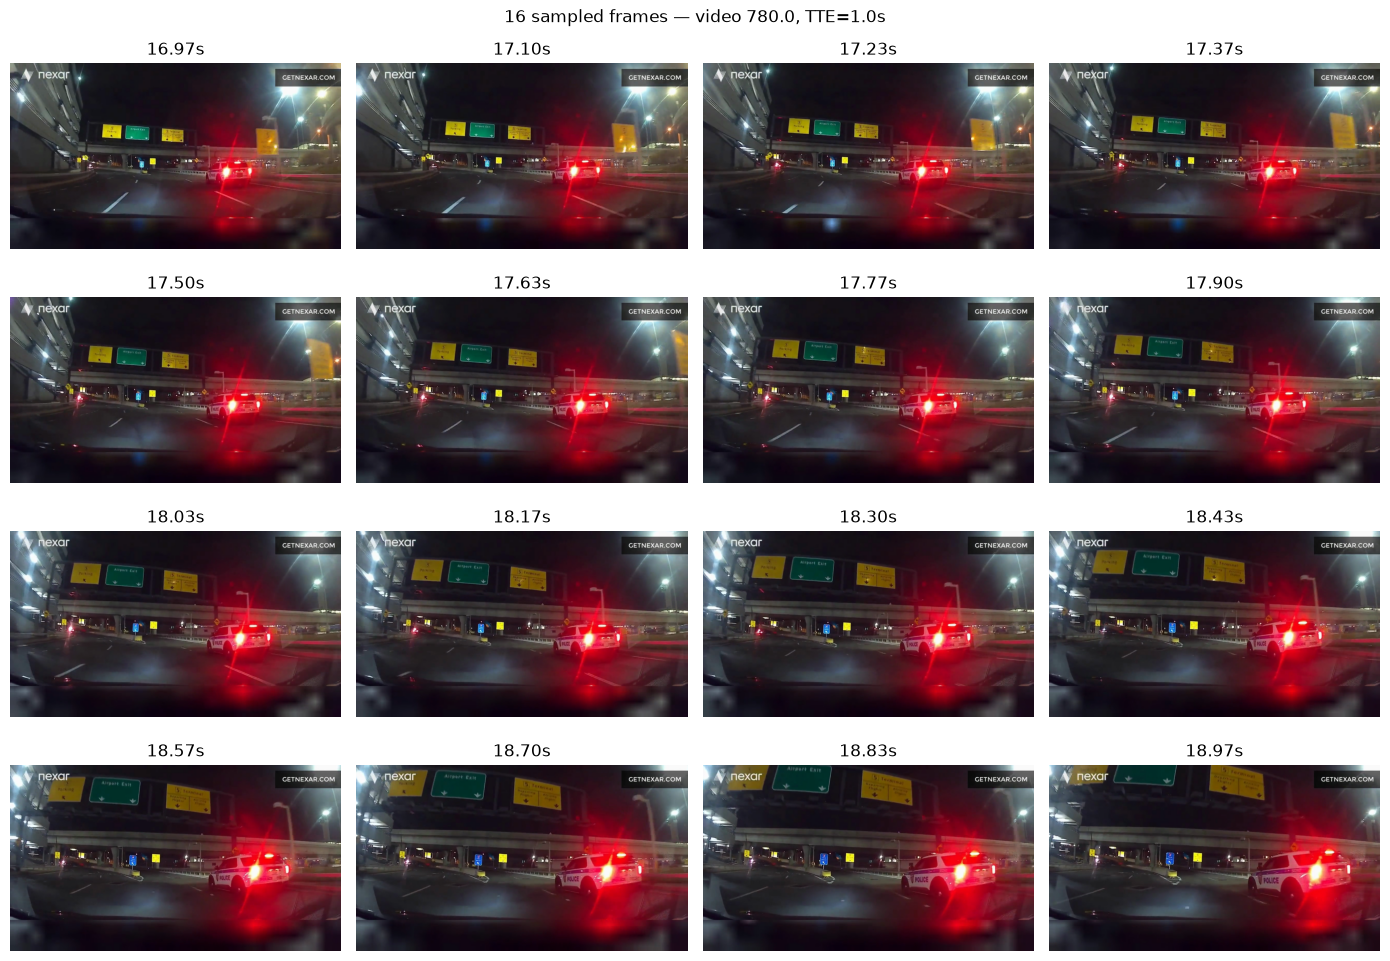

In [21]:
# Display the sampled frames.

figure, axes = plt.subplots(4, 4, figsize=(14, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(frames[i])
    ax.set_title(f"{actual_times[i]:.2f}s")
    ax.axis("off")

plt.suptitle(
    f"16 sampled frames — video {example_row['id']}, TTE={example_row['tte']}s"
)
plt.tight_layout()
plt.show()

## 3. Load the pretrained CNN

We use ResNet-18 with ImageNet pretrained weights.

The final classification layer is removed.

Therefore:

**RGB frame → ResNet-18 → 512-dimensional feature vector**

The ResNet weights are frozen in this first experiment. We are not trying to fine-tune the CNN yet.

This gives us a clean first learned representation while keeping computation reasonable.

In [22]:
weights = ResNet18_Weights.DEFAULT

cnn = resnet18(weights=weights)

# Remove the final ImageNet classification layer.
cnn.fc = nn.Identity()

cnn = cnn.to(DEVICE)
cnn.eval()

# Freeze all CNN parameters.
for parameter in cnn.parameters():
    parameter.requires_grad = False

preprocess = weights.transforms()

FEATURE_DIM = 512

print("CNN:", "ResNet-18")
print("Feature dimension:", FEATURE_DIM)
print("Parameters frozen:", all(not p.requires_grad for p in cnn.parameters()))

CNN: ResNet-18
Feature dimension: 512
Parameters frozen: True


## 4. Extract CNN features for one clip

For each clip:

1. Read 16 RGB frames.
2. Apply the pretrained ResNet preprocessing.
3. Pass the 16 frames through ResNet-18.
4. Store the resulting sequence of 16 feature vectors.

The resulting representation has shape:

**(16, 512)**

The first dimension is temporal order and the second dimension contains the learned visual representation of each frame.

In [23]:
from PIL import Image


def extract_clip_features(video_id, clip_start, clip_end):
    video_path = get_video_path(video_id)

    frames, actual_times, fps = read_clip_frames(
        video_path,
        clip_start,
        clip_end,
        NUM_FRAMES
    )

    tensors = []

    for frame in frames:

        # OpenCV gave us an RGB NumPy array.
        # torchvision's pretrained ResNet transform expects a PIL image.
        pil_image = Image.fromarray(frame)

        tensor = preprocess(pil_image)

        tensors.append(tensor)

    # Combine the 16 individual frame tensors into one batch.
    batch = torch.stack(tensors).to(DEVICE)

    # CNN is frozen, so gradients are not needed.
    with torch.no_grad():
        features = cnn(batch)

    # Move the result back to CPU and convert to NumPy.
    features = features.detach().cpu().numpy()

    return features.astype(np.float32), actual_times

In [24]:
example_features, example_feature_times = extract_clip_features(
    example_row["id"],
    example_row["clip_start"],
    example_row["clip_end"]
)

print("Feature shape:", example_features.shape)
print("Expected shape:", (NUM_FRAMES, FEATURE_DIM))
print("Feature dtype:", example_features.dtype)
print("Feature times:", example_feature_times)

Feature shape: (16, 512)
Expected shape: (16, 512)
Feature dtype: float32
Feature times: [16.96666667 17.1        17.23333333 17.36666667 17.5        17.63333333
 17.76666667 17.9        18.03333333 18.16666667 18.3        18.43333333
 18.56666667 18.7        18.83333333 18.96666667]


## 5. Cache CNN features

Feature extraction is the expensive part of this notebook.

We therefore process each TTE once and save the resulting arrays.

For each TTE we save:

- `X_train`: shape `(number_of_clips, 16, 512)`
- `y_train`: shape `(number_of_clips,)`
- `X_val`: shape `(number_of_clips, 16, 512)`
- `y_val`: shape `(number_of_clips,)`

If a saved feature file already exists, the notebook loads it instead of extracting it again.

This means that if training the LSTM changes later, we do **not** need to decode the MP4 files again.

In [25]:
def extract_features_for_dataframe(
    clips_df,
    split_name,
    tte,
    output_path
):
    subset = clips_df[
        clips_df["tte"] == tte
    ].reset_index(drop=True)

    if output_path.exists():
        print(f"Loading cached features: {output_path}")
        return np.load(output_path)

    print(
        f"Extracting {len(subset)} clips "
        f"for {split_name}, TTE={tte:.1f}s"
    )

    all_features = []

    start_time = time.time()

    for index, row in subset.iterrows():

        features, _ = extract_clip_features(
            row["id"],
            row["clip_start"],
            row["clip_end"]
        )

        all_features.append(features)

        if (index + 1) % 50 == 0 or index == 0:
            elapsed = time.time() - start_time
            print(
                f"{index + 1}/{len(subset)} clips "
                f"({elapsed / 60:.1f} min)"
            )

    all_features = np.stack(all_features).astype(np.float32)

    np.save(output_path, all_features)

    elapsed = time.time() - start_time

    print(
        f"Saved {output_path} | "
        f"shape={all_features.shape} | "
        f"time={elapsed / 60:.1f} min"
    )

    return all_features

In [ ]:
problem_video_id = 1734

problem_row = train_clips[
    (train_clips["id"].astype(float) == problem_video_id) &
    (train_clips["tte"] == 0.5)
].iloc[0]

problem_video_path = get_video_path(problem_video_id)

frames, actual_times, fps = read_clip_frames(
    problem_video_path,
    problem_row["clip_start"],
    problem_row["clip_end"],
    NUM_FRAMES
)

print("Frames shape:", frames.shape)
print("Actual times:")
print(actual_times)

print("\nLast frame time:", actual_times[-1])
print("Prediction time:", problem_row["prediction_time"])

print("\nTemporal leakage:")
print(np.any(actual_times > problem_row["prediction_time"]))

Video ID: 1734
Path: data/raw/train/01734.mp4
FPS: 30.0
Frame count: 570
Calculated duration: 19.0

Clip metadata:
TTE: 0.5
Prediction time: 19.0
Clip start: 17.0
Clip end: 19.0

Requested frame times:
[17.         17.13333333 17.26666667 17.4        17.53333333 17.66666667
 17.8        17.93333333 18.06666667 18.2        18.33333333 18.46666667
 18.6        18.73333333 18.86666667 19.        ]

Requested frame numbers:
[510 514 518 522 526 530 534 538 542 546 550 554 558 562 566 570]


In [17]:
# Extract/cache features for every TTE.

train_features = {}
val_features = {}

for tte in TTE_VALUES:

    train_feature_path = (
        FEATURE_DIR / f"train_tte_{tte:.1f}.npy"
    )

    val_feature_path = (
        FEATURE_DIR / f"val_tte_{tte:.1f}.npy"
    )

    train_features[tte] = extract_features_for_dataframe(
        train_clips,
        "train",
        tte,
        train_feature_path
    )

    val_features[tte] = extract_features_for_dataframe(
        val_clips,
        "validation",
        tte,
        val_feature_path
    )

print("\nFeature extraction/cache stage complete.")

Extracting 1200 clips for train, TTE=0.5s
1/1200 clips (0.0 min)
50/1200 clips (0.6 min)
100/1200 clips (1.1 min)
150/1200 clips (1.7 min)
200/1200 clips (2.3 min)
250/1200 clips (2.8 min)
300/1200 clips (3.4 min)
350/1200 clips (3.8 min)
400/1200 clips (4.4 min)


ValueError: Could not read frame 570 from data/raw/train/01734.mp4

In [ ]:
# Save labels separately.
# Labels come directly from the fixed clip metadata.

train_labels = {}
val_labels = {}

for tte in TTE_VALUES:

    train_subset = train_clips[
        train_clips["tte"] == tte
    ].reset_index(drop=True)

    val_subset = val_clips[
        val_clips["tte"] == tte
    ].reset_index(drop=True)

    train_labels[tte] = train_subset["target"].astype(np.float32).to_numpy()
    val_labels[tte] = val_subset["target"].astype(np.float32).to_numpy()

    print(
        f"TTE {tte:.1f}s | "
        f"train features={train_features[tte].shape}, "
        f"train labels={train_labels[tte].shape}, "
        f"val features={val_features[tte].shape}, "
        f"val labels={val_labels[tte].shape}"
    )

## 6. Build the temporal dataset

The CNN has produced a sequence:

```text
16 frames
   ↓
16 × 512 features
```

The LSTM will receive this sequence in temporal order.

Each training example therefore has:

**X = `(16, 512)`**

and

**y = `0` or `1`**

In [ ]:
class TemporalFeatureDataset(Dataset):

    def __init__(self, features, labels):
        self.features = torch.tensor(
            features,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.features[index], self.labels[index]

## 7. Define the LSTM model

The LSTM reads the 16 frame features in order.

We use the final hidden state as the summary of the observed video sequence.

That summary is passed through a linear layer to produce one collision logit.

During training we use `BCEWithLogitsLoss`, so the model itself does not need a sigmoid layer.

At evaluation time we apply sigmoid to obtain a probability.

In [ ]:
class CNNLSTM(nn.Module):

    def __init__(
        self,
        input_size=512,
        hidden_size=128,
        num_layers=1,
        dropout=0.0
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.classifier = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        sequence_output, (hidden_state, cell_state) = self.lstm(x)

        # Final LSTM hidden state.
        final_hidden = hidden_state[-1]

        logits = self.classifier(
            final_hidden
        ).squeeze(1)

        return logits

## 8. Training and evaluation functions

The model is trained independently for each TTE.

We use:

- Adam optimizer
- Binary cross-entropy with logits
- The same fixed validation set
- Average Precision as the main validation metric

We keep the best model according to validation AP rather than simply taking the final epoch.

In [ ]:
def calculate_metrics(y_true, y_probability):

    y_prediction = (
        y_probability >= 0.5
    ).astype(int)

    return {
        "AP": average_precision_score(
            y_true,
            y_probability
        ),
        "ROC_AUC": roc_auc_score(
            y_true,
            y_probability
        ),
        "Precision": precision_score(
            y_true,
            y_prediction,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            y_prediction,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            y_prediction,
            zero_division=0
        )
    }


def predict_probabilities(model, data_loader):

    model.eval()

    all_probabilities = []
    all_labels = []

    with torch.no_grad():

        for features, labels in data_loader:

            features = features.to(DEVICE)

            logits = model(features)

            probabilities = torch.sigmoid(
                logits
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_probabilities)
    )

In [ ]:
def train_one_tte(
    tte,
    train_X,
    train_y,
    val_X,
    val_y
):

    train_dataset = TemporalFeatureDataset(
        train_X,
        train_y
    )

    val_dataset = TemporalFeatureDataset(
        val_X,
        val_y
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE_LSTM,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE_LSTM,
        shuffle=False
    )

    model = CNNLSTM(
        input_size=FEATURE_DIM,
        hidden_size=HIDDEN_SIZE,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.BCEWithLogitsLoss()

    best_ap = -np.inf
    best_state = None

    history = []

    print(f"\nTraining CNN + LSTM for TTE={tte:.1f}s")
    print(f"Training examples: {len(train_dataset)}")
    print(f"Validation examples: {len(val_dataset)}")

    for epoch in range(NUM_EPOCHS):

        model.train()

        total_loss = 0.0

        for features, labels in train_loader:

            features = features.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            logits = model(features)

            loss = criterion(
                logits,
                labels
            )

            loss.backward()
            optimizer.step()

            total_loss += (
                loss.item() * len(labels)
            )

        train_loss = (
            total_loss / len(train_dataset)
        )

        y_val, val_probability = predict_probabilities(
            model,
            val_loader
        )

        metrics = calculate_metrics(
            y_val,
            val_probability
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            **metrics
        })

        print(
            f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} | "
            f"loss={train_loss:.4f} | "
            f"val AP={metrics['AP']:.4f} | "
            f"val ROC-AUC={metrics['ROC_AUC']:.4f}"
        )

        if metrics["AP"] > best_ap:

            best_ap = metrics["AP"]

            best_state = copy.deepcopy(
                model.state_dict()
            )

    model.load_state_dict(best_state)

    history_df = pd.DataFrame(history)

    return model, history_df

## 9. Train the CNN + LSTM models

We now train one model for each prediction horizon:

- TTE = 0.5 s
- TTE = 1.0 s
- TTE = 1.5 s

This is the main learned-model experiment.

The CNN features are already cached, so this stage should be substantially faster than video feature extraction.

In [ ]:
temporal_models = {}
temporal_histories = {}
temporal_results = []

for tte in TTE_VALUES:

    model, history_df = train_one_tte(
        tte,
        train_features[tte],
        train_labels[tte],
        val_features[tte],
        val_labels[tte]
    )

    temporal_models[tte] = model
    temporal_histories[tte] = history_df

    best_row = history_df.loc[
        history_df["AP"].idxmax()
    ]

    temporal_results.append({
        "model": "cnn_lstm",
        "tte": tte,
        "AP": best_row["AP"],
        "ROC_AUC": best_row["ROC_AUC"],
        "Precision": best_row["Precision"],
        "Recall": best_row["Recall"],
        "F1": best_row["F1"],
        "best_epoch": int(best_row["epoch"])
    })

temporal_results_df = pd.DataFrame(
    temporal_results
)

temporal_results_df

## 10. Plot training behaviour

The validation AP is more important than training loss for our research question.

We inspect the learning curves mainly to check whether:

- the model is learning at all,
- validation performance improves,
- the model begins to overfit,
- more epochs are likely to be useful.

In [ ]:
for tte in TTE_VALUES:

    history_df = temporal_histories[tte]

    plt.figure(figsize=(9, 5))

    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        marker="o",
        label="Training Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Binary Cross-Entropy Loss")
    plt.title(
        f"CNN + LSTM Training Loss — TTE={tte:.1f}s"
    )

    plt.grid(True)
    plt.legend()

    plt.show()

    plt.figure(figsize=(9, 5))

    plt.plot(
        history_df["epoch"],
        history_df["AP"],
        marker="o",
        label="Validation AP"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Average Precision")
    plt.title(
        f"CNN + LSTM Validation AP — TTE={tte:.1f}s"
    )

    plt.grid(True)
    plt.legend()

    plt.show()

## 11. Final CNN + LSTM validation evaluation

The best checkpoint for each TTE was selected using validation AP.

We now calculate the complete metric set for those selected models.

In [ ]:
final_temporal_results = []

for tte in TTE_VALUES:

    model = temporal_models[tte]

    val_dataset = TemporalFeatureDataset(
        val_features[tte],
        val_labels[tte]
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE_LSTM,
        shuffle=False
    )

    y_val, y_probability = predict_probabilities(
        model,
        val_loader
    )

    metrics = calculate_metrics(
        y_val,
        y_probability
    )

    final_temporal_results.append({
        "model": "cnn_lstm",
        "tte": tte,
        **metrics
    })

final_temporal_results_df = pd.DataFrame(
    final_temporal_results
)

final_temporal_results_df

## 12. Compare CNN + LSTM against the final baselines

Notebook 4 saved the final baseline results in:

`results/baseline_results.csv`

We now combine those results with the learned temporal model.

This is the first major comparison in the project.

In [ ]:
baseline_results_path = RESULTS_DIR / "baseline_results.csv"

baseline_results_df = pd.read_csv(
    baseline_results_path
)

print("Baseline results:")
display(baseline_results_df)

print("CNN + LSTM results:")
display(final_temporal_results_df)

combined_results = pd.concat(
    [
        baseline_results_df,
        final_temporal_results_df
    ],
    ignore_index=True
)

combined_results

In [ ]:
# Presentation-friendly model names.

combined_results["model_display"] = combined_results[
    "model"
].replace({
    "naive": "Naive",
    "optical_flow_scaled": "Optical Flow",
    "cnn_lstm": "CNN + LSTM"
})

combined_results

## 13. Main comparison plot — Average Precision vs TTE

This is one of the most important figures for the report.

The x-axis represents how far before the event the prediction must be made.

The y-axis represents Average Precision.

A model that maintains useful AP as TTE increases is able to make predictions further in advance.

In [ ]:
plt.figure(figsize=(10, 6))

for model_name in combined_results["model_display"].unique():

    model_results = combined_results[
        combined_results["model_display"] == model_name
    ].sort_values("tte")

    plt.plot(
        model_results["tte"],
        model_results["AP"],
        marker="o",
        label=model_name
    )

plt.xlabel("Time To Event (seconds)")
plt.ylabel("Average Precision")
plt.title(
    "Collision Prediction Performance Across Prediction Horizons"
)

plt.xticks(TTE_VALUES)
plt.grid(True)
plt.legend()

plt.show()

## 14. Final results table

This table is the main quantitative result produced by Notebook 5.

Do not interpret the numbers as a conclusion yet. The final report should interpret them only after all planned experiments and checks have been completed.

In [ ]:
final_comparison_table = combined_results[
    [
        "model_display",
        "tte",
        "AP",
        "ROC_AUC",
        "Precision",
        "Recall",
        "F1"
    ]
].sort_values(
    ["tte", "model_display"]
).reset_index(drop=True)

final_comparison_table

## 15. Save learned-model and combined results

We save both:

1. The CNN + LSTM results by themselves.
2. The combined baseline + CNN + LSTM table.

These files will later be used by the final analysis/report notebook.

In [ ]:
temporal_results_path = (
    RESULTS_DIR / "cnn_lstm_results.csv"
)

combined_results_path = (
    RESULTS_DIR / "baseline_and_cnn_lstm_results.csv"
)

final_temporal_results_df.to_csv(
    temporal_results_path,
    index=False
)

final_comparison_table.to_csv(
    combined_results_path,
    index=False
)

print("Saved:")
print(temporal_results_path)
print(combined_results_path)

## 16. Save model checkpoints

The best model for each TTE is saved so that we can reuse it later without retraining.

These checkpoint files are experimental outputs and should normally be excluded from Git using `.gitignore`.

In [ ]:
for tte, model in temporal_models.items():

    checkpoint_path = (
        RESULTS_DIR / f"cnn_lstm_tte_{tte:.1f}.pt"
    )

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "tte": tte,
            "feature_dim": FEATURE_DIM,
            "hidden_size": HIDDEN_SIZE,
            "num_layers": NUM_LAYERS,
            "random_seed": RANDOM_SEED,
        },
        checkpoint_path
    )

    print("Saved:", checkpoint_path)

# Preliminary Conclusions

Notebook 5 has now completed the first learned temporal model.

The experiment should answer three immediate questions:

1. **Does CNN + LSTM learn better than the naive baseline?**
2. **How does CNN + LSTM performance change from 0.5 s to 1.5 s TTE?**
3. **How does the learned temporal representation compare with the classical optical-flow baseline?**

Do not write the final research conclusion yet.

The next stage should be analysis and controlled ablation, especially checking whether the LSTM is actually using temporal order rather than simply recognising individual frames.

## Important outputs

The main files produced are:

```text
data/processed/cnn_features/
results/cnn_lstm_results.csv
results/baseline_and_cnn_lstm_results.csv
results/cnn_lstm_tte_0.5.pt
results/cnn_lstm_tte_1.0.pt
results/cnn_lstm_tte_1.5.pt
```

## Next notebook

The next major experiment should be a **temporal-order ablation**:

**correct frame order vs shuffled frame order**

This will help determine whether temporal information itself contributes to collision prediction.